# Capstone I: Mutual Fund Analytics
## Notebook: Advanced Analytics and Risk Metrics

**Goal:** measure each scheme's return and risk from its daily NAV history, compare it with its benchmark, and check the figures against the provider's reported metrics.

**Sections**
1. Setup, assumptions and data
2. Daily returns
3. Return and risk metrics per scheme
4. Benchmark-relative metrics (beta, alpha, tracking error, capture ratios)
5. Compare with reported metrics
6. Visualisations
7. Market stress days
8. Save results and key findings

### Metric definitions
| Metric | Meaning | Formula |
|---|---|---|
| CAGR | Compound annual growth rate | (end NAV / start NAV)^(1/years) - 1 |
| Volatility | Annualised standard deviation of daily returns | std(daily) x sqrt(252) |
| Sharpe ratio | Excess return per unit of total risk | (annual return - risk-free) / volatility |
| Sortino ratio | Excess return per unit of downside risk | (annual return - risk-free) / downside deviation |
| Max drawdown | Largest peak-to-trough fall | min(NAV / running peak - 1) |
| Calmar ratio | Return per unit of drawdown | CAGR / abs(max drawdown) |
| VaR (95%) | Daily loss exceeded on only 5% of days | 5th percentile of daily returns |
| CVaR (95%) | Average loss on those worst 5% days | mean of returns at or below VaR |
| Beta | Sensitivity to the benchmark | cov(fund, benchmark) / var(benchmark) |
| Alpha (Jensen) | Annual return beyond what beta explains | (fund - rf) - beta x (benchmark - rf), annualised |
| Tracking error | Volatility of the gap to the benchmark | std(fund - benchmark) x sqrt(252) |
| Information ratio | Active return per unit of tracking error | (fund - benchmark return) / tracking error |

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)


def find_processed():
    """Works from notebooks/ (data in ../data/processed), from the project root, or next to the CSVs."""
    for cand in (Path("../data/processed"), Path("data/processed"), Path(".")):
        if cand.exists() and list(cand.glob("*fund_master_clean.csv")):
            return cand
    raise FileNotFoundError(
        "Cleaned CSVs not found. Keep this notebook in notebooks/ (CSVs in ../data/processed) "
        "or put it in the same folder as the *_clean.csv files."
    )


PROC = Path.home() /"processed"
FIG = Path.home() / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Reading from:", PROC)
print("Figures to  :", FIG)


def load(name, dates=()):
    df = pd.read_csv(PROC / f"{name}_clean.csv")
    for c in dates:
        df[c] = pd.to_datetime(df[c])
    return df


def save_fig(name):
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

Reading from: C:\Users\Sakshi Mane\processed
Figures to  : C:\Users\Sakshi Mane\reports\figures


In [2]:
RF = 0.065        # annual risk-free rate (assumption: roughly the Indian 10-year government bond yield); change if needed
TD = 252          # trading days per year
CONF = 0.95       # VaR / CVaR confidence level

fm = load("fund_master", ["launch_date"])
nav = load("nav_history", ["date"])
bm = load("benchmark_indices", ["date"])
perf = load("scheme_performance")

# Use real reported NAVs only; forward-filled weekend rows would add fake zero-return days
nav_td = nav[nav["is_filled"] == 0] if "is_filled" in nav.columns else nav

# fund_master benchmark names -> index names used in benchmark_indices
BM_MAP = {
    "NIFTY 50 TRI": "NIFTY50",
    "NIFTY 100 TRI": "NIFTY100",
    "NIFTY 500 TRI": "NIFTY500",
    "NIFTY Midcap 150 TRI": "NIFTY_MIDCAP150",
    "NIFTY Midcap 50 TRI": "NIFTY_MIDCAP150",          # nearest available index
    "NIFTY Large Midcap 250 TRI": "NIFTY500",          # nearest available index
    "BSE 250 SmallCap TRI": "BSE_SMALLCAP",
    "CRISIL Liquid Fund AI Index": "CRISIL_LIQUID",
    "CRISIL Dynamic Gilt Index": "CRISIL_GILT",
    "CRISIL Short Term Bond Index": "CRISIL_LIQUID",   # nearest available index
}
fm["bm_index"] = fm["benchmark"].map(BM_MAP)
print("Funds without a benchmark mapping:", int(fm["bm_index"].isna().sum()))
print("Risk-free rate:", f"{RF:.1%}", "| trading days:", TD)
fm.groupby(["benchmark", "bm_index"]).size().rename("funds").reset_index()

Funds without a benchmark mapping: 0
Risk-free rate: 6.5% | trading days: 252


,benchmark,bm_index,funds
0,BSE 250 SmallCap TRI,BSE_SMALLCAP,6
1,CRISIL Dynamic Gilt Index,CRISIL_GILT,2
2,CRISIL Liquid Fund AI Index,CRISIL_LIQUID,3
3,CRISIL Short Term Bond Index,CRISIL_LIQUID,1
4,NIFTY 100 TRI,NIFTY100,14
5,NIFTY 50 TRI,NIFTY50,2
6,NIFTY 500 TRI,NIFTY500,4
7,NIFTY Large Midcap 250 TRI,NIFTY500,1
8,NIFTY Midcap 150 TRI,NIFTY_MIDCAP150,6
9,NIFTY Midcap 50 TRI,NIFTY_MIDCAP150,1


In [3]:
nav_p = nav_td.pivot(index="date", columns="amfi_code", values="nav").sort_index()
ret = nav_p.pct_change().dropna(how="all")
bm_p = bm.pivot(index="date", columns="index_name", values="close_value").sort_index()
bm_ret = bm_p.pct_change().dropna(how="all")
print("Fund returns     :", ret.shape, "(days x funds)")
print("Benchmark returns:", bm_ret.shape)
print("Largest single-day fund move: ", f"{ret.abs().max().max():.2%}")

Fund returns     : (1149, 40) (days x funds)
Benchmark returns: (1149, 7)
Largest single-day fund move:  6.47%


In [4]:
rf_d = RF / TD


def fund_metrics(code_):
    r = ret[code_].dropna()
    s = nav_p[code_].dropna()
    years = (s.index[-1] - s.index[0]).days / 365.25
    cagr = (s.iloc[-1] / s.iloc[0]) ** (1 / years) - 1
    ann_ret = r.mean() * TD
    vol = r.std() * np.sqrt(TD)
    downside = np.sqrt(np.mean(np.minimum(r - rf_d, 0) ** 2)) * np.sqrt(TD)
    mdd = (s / s.cummax() - 1).min()
    var = np.percentile(r, (1 - CONF) * 100)
    return {
        "amfi_code": code_, "years": years, "cagr": cagr, "ann_return": ann_ret, "volatility": vol,
        "sharpe": (ann_ret - RF) / vol, "sortino": (ann_ret - RF) / downside,
        "max_drawdown": mdd, "calmar": cagr / abs(mdd) if mdd else np.nan,
        "var_95": var, "cvar_95": r[r <= var].mean(),
        "best_day": r.max(), "worst_day": r.min(), "pct_positive_days": (r > 0).mean(),
    }


risk = pd.DataFrame([fund_metrics(c) for c in ret.columns])
risk = fm[["amfi_code", "scheme_name", "fund_house", "category", "sub_category", "plan", "benchmark", "bm_index"]].merge(risk, on="amfi_code")
risk[["scheme_name", "cagr", "volatility", "sharpe", "sortino", "max_drawdown", "var_95"]].sort_values("sharpe", ascending=False).head(10)

,scheme_name,cagr,volatility,sharpe,sortino,max_drawdown,var_95
34,Mirae Asset Large Cap Fund - Regular - Growth,0.31,0.14,1.45,2.18,-0.11,-0.01
22,Kotak Flexicap Fund - Regular - Growth,0.31,0.16,1.31,2.02,-0.13,-0.01
36,Mirae Asset Tax Saver Fund - Regular - Growth,0.32,0.18,1.23,1.88,-0.16,-0.02
0,SBI Bluechip Fund - Regular Plan - Growth,0.26,0.14,1.21,1.84,-0.15,-0.01
12,ICICI Pru Midcap Fund - Regular - Growth,0.33,0.19,1.18,1.78,-0.18,-0.02
38,DSP Midcap Fund - Regular - Growth,0.30,0.18,1.13,1.67,-0.17,-0.02
7,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,0.30,0.19,1.09,1.63,-0.16,-0.02
15,Nippon India Large Cap Fund - Regular - Growth,0.24,0.14,1.08,1.61,-0.17,-0.01
28,ABSL Frontline Equity Fund - Regular - Growth,0.24,0.15,1.03,1.55,-0.11,-0.01
11,ICICI Pru Bluechip Fund - Direct - Growth,0.23,0.14,1.03,1.54,-0.13,-0.01


In [5]:
def bench_metrics(row):
    r = ret[row["amfi_code"]].dropna()
    b = bm_ret[row["bm_index"]].reindex(r.index).dropna()
    r = r.reindex(b.index)
    beta = np.cov(r, b)[0, 1] / np.var(b, ddof=1)
    alpha = ((r.mean() - rf_d) - beta * (b.mean() - rf_d)) * TD
    te = (r - b).std() * np.sqrt(TD)
    active = (r.mean() - b.mean()) * TD
    up, down = b > 0, b < 0
    return pd.Series({
        "beta": beta, "alpha": alpha, "r_squared": np.corrcoef(r, b)[0, 1] ** 2,
        "tracking_error": te, "info_ratio": active / te if te else np.nan,
        "up_capture": r[up].mean() / b[up].mean(), "down_capture": r[down].mean() / b[down].mean(),
        "benchmark_cagr": (bm_p[row["bm_index"]].iloc[-1] / bm_p[row["bm_index"]].iloc[0]) ** (365.25 / (bm_p.index[-1] - bm_p.index[0]).days) - 1,
    })


risk = pd.concat([risk, risk.apply(bench_metrics, axis=1)], axis=1)
risk["excess_cagr"] = risk["cagr"] - risk["benchmark_cagr"]
print("Funds beating their benchmark (CAGR):", int((risk["excess_cagr"] > 0).sum()), "of", len(risk))
risk[["scheme_name", "beta", "alpha", "r_squared", "tracking_error", "info_ratio", "excess_cagr"]].sort_values("alpha", ascending=False).head(10)

Funds beating their benchmark (CAGR): 23 of 40


,scheme_name,beta,alpha,r_squared,tracking_error,info_ratio,excess_cagr
2,SBI Small Cap Fund - Regular Plan - Growth,-0.05,0.25,0.00,0.34,0.12,0.05
39,DSP Small Cap Fund - Regular - Growth,0.03,0.23,0.00,0.33,0.12,0.04
12,ICICI Pru Midcap Fund - Regular - Growth,-0.00,0.23,0.00,0.26,0.04,0.01
36,Mirae Asset Tax Saver Fund - Regular - Growth,0.04,0.21,0.00,0.22,0.31,0.08
22,Kotak Flexicap Fund - Regular - Growth,-0.02,0.21,0.00,0.21,0.27,0.07
34,Mirae Asset Large Cap Fund - Regular - Growth,0.02,0.21,0.00,0.19,1.26,0.29
38,DSP Midcap Fund - Regular - Growth,-0.01,0.20,0.00,0.25,-0.07,-0.02
26,Axis Midcap Fund - Regular - Growth,-0.04,0.20,0.00,0.27,-0.09,-0.04
7,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,0.03,0.20,0.00,0.26,-0.04,-0.02
0,SBI Bluechip Fund - Regular Plan - Growth,-0.03,0.16,0.00,0.19,1.05,0.23


In [6]:
avg_r2 = risk["r_squared"].mean()
print(f"Average R-squared between fund and benchmark daily returns: {avg_r2:.3f}")
if avg_r2 < 0.10:
    print("DATA WARNING: these NAV series barely move with their benchmark indices (R-squared near 0).")
    print("NAV-derived beta, alpha, tracking error and capture ratios are therefore NOT meaningful for this dataset.")
    print("Use the reported beta/alpha in scheme_performance for benchmark-relative analysis, and rely on the NAV-based")
    print("volatility, Sharpe, Sortino, drawdown and VaR, which depend only on each fund's own history.")
else:
    print("Funds track their benchmarks, so the benchmark-relative metrics are reliable.")

Average R-squared between fund and benchmark daily returns: 0.001
DATA WARNING: these NAV series barely move with their benchmark indices (R-squared near 0).
NAV-derived beta, alpha, tracking error and capture ratios are therefore NOT meaningful for this dataset.
Use the reported beta/alpha in scheme_performance for benchmark-relative analysis, and rely on the NAV-based
volatility, Sharpe, Sortino, drawdown and VaR, which depend only on each fund's own history.


In [7]:
cmp = risk.merge(perf[["amfi_code", "sharpe_ratio", "std_dev_ann_pct", "max_drawdown_pct", "beta", "alpha"]], on="amfi_code", suffixes=("", "_reported"))
pairs = [("sharpe", "sharpe_ratio", 1), ("volatility", "std_dev_ann_pct", 100), ("max_drawdown", "max_drawdown_pct", 100), ("beta", "beta_reported", 1)]
rows = []
for mine, reported, scale in pairs:
    a, b = cmp[mine] * scale, cmp[reported]
    rows.append({"metric": mine, "correlation": a.corr(b), "my_mean": a.mean(), "reported_mean": b.mean(), "mean_difference": (a - b).mean()})
agree = pd.DataFrame(rows)
agree

,metric,correlation,my_mean,reported_mean,mean_difference
0,sharpe,-0.33,0.54,1.36,-0.82
1,volatility,1.00,14.94,14.96,-0.02
2,max_drawdown,0.32,-17.87,-19.20,1.33
3,beta,0.05,-0.00,0.87,-0.88


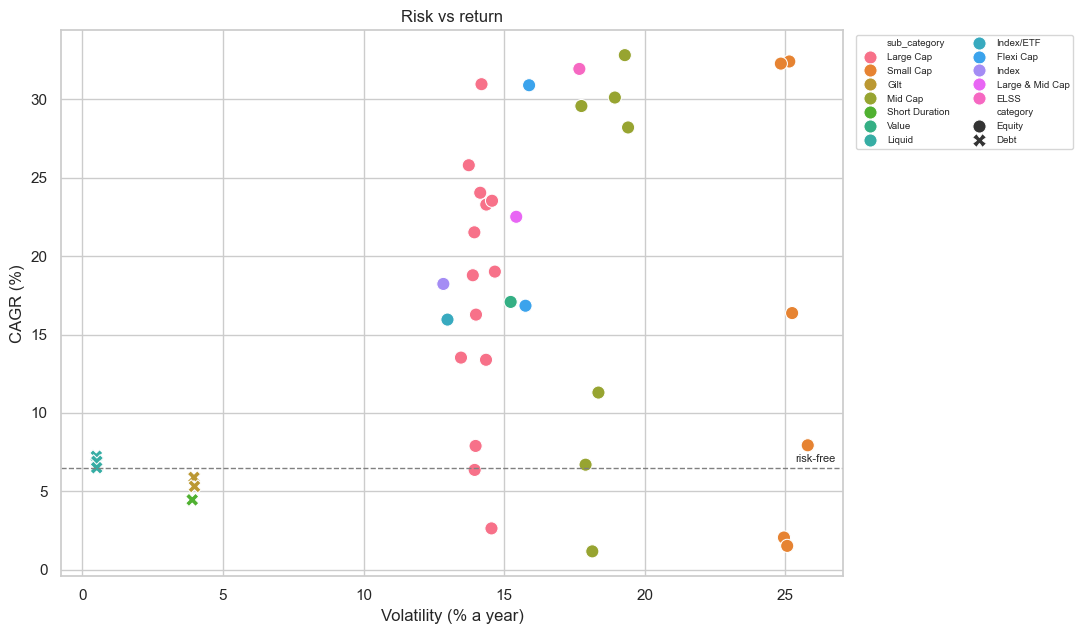

In [8]:
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.scatterplot(data=risk, x=risk["volatility"] * 100, y=risk["cagr"] * 100, hue="sub_category", style="category", s=90, ax=ax)
ax.axhline(RF * 100, color="grey", ls="--", lw=1); ax.text(ax.get_xlim()[1] * 0.99, RF * 100 + 0.4, "risk-free", ha="right", fontsize=8)
ax.set_xlabel("Volatility (% a year)"); ax.set_ylabel("CAGR (%)"); ax.set_title("Risk vs return")
ax.legend(fontsize=7, ncol=2, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); save_fig("risk_return_scatter"); plt.show()

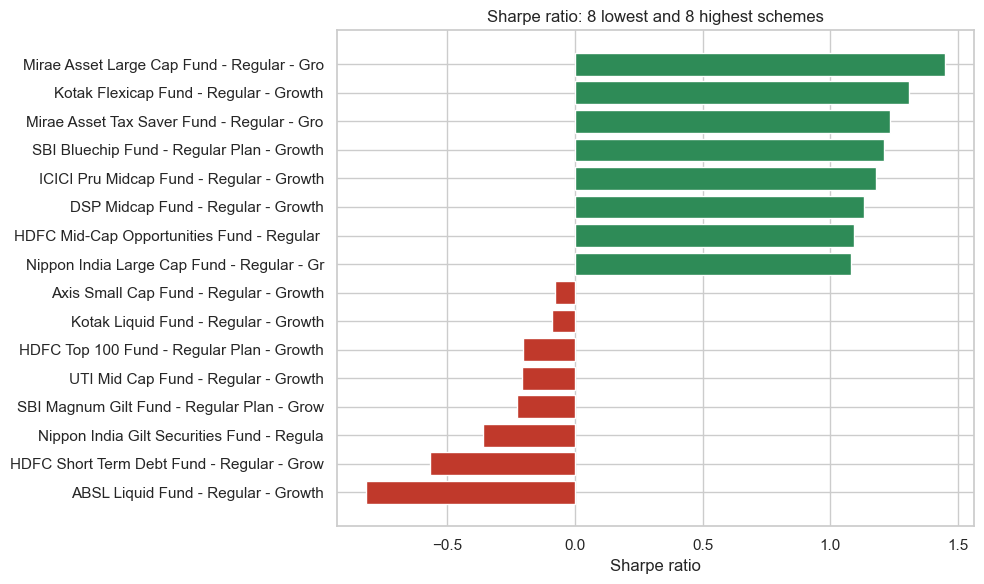

In [9]:
ordered = risk.sort_values("sharpe")
pick = pd.concat([ordered.head(8), ordered.tail(8)])
plt.figure(figsize=(10, 6))
plt.barh(pick["scheme_name"].str[:42], pick["sharpe"], color=np.where(pick["sharpe"] >= 0, "#2E8B57", "#C0392B"))
plt.title("Sharpe ratio: 8 lowest and 8 highest schemes"); plt.xlabel("Sharpe ratio")
plt.tight_layout(); save_fig("risk_sharpe_extremes"); plt.show()

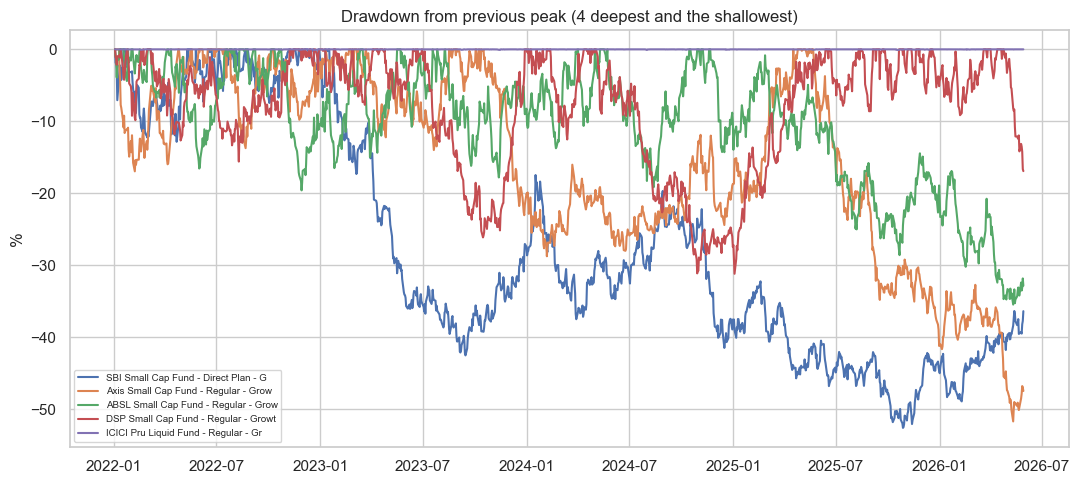

In [10]:
dd = nav_p / nav_p.cummax() - 1
worst4 = risk.nsmallest(4, "max_drawdown")["amfi_code"].tolist()
best_dd = risk.nlargest(1, "max_drawdown")["amfi_code"].tolist()
names = fm.set_index("amfi_code")["scheme_name"]
plt.figure(figsize=(11, 5))
for c in worst4 + best_dd:
    plt.plot(dd.index, dd[c] * 100, label=names[c][:36])
plt.title("Drawdown from previous peak (4 deepest and the shallowest)"); plt.ylabel("%"); plt.legend(fontsize=7)
plt.tight_layout(); save_fig("risk_drawdowns"); plt.show()

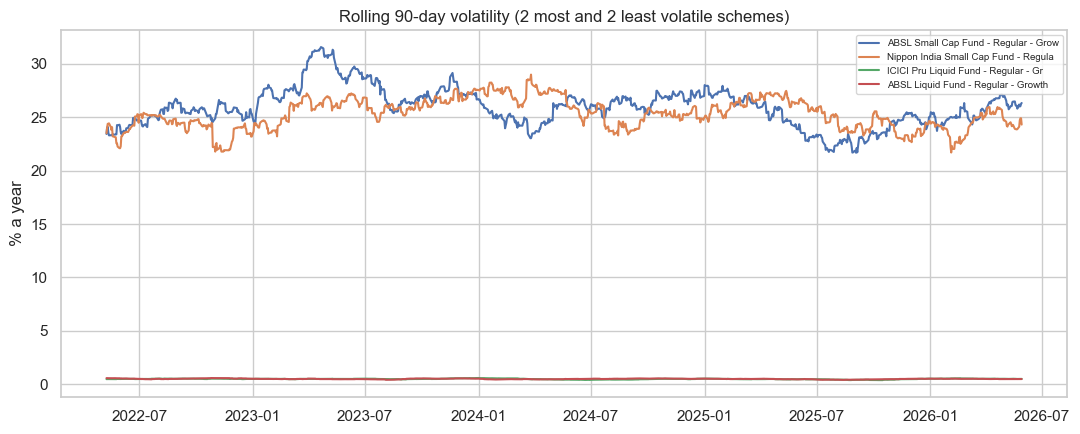

In [11]:
roll = ret.rolling(90).std() * np.sqrt(TD) * 100
hi, lo = risk.nlargest(2, "volatility")["amfi_code"].tolist(), risk.nsmallest(2, "volatility")["amfi_code"].tolist()
plt.figure(figsize=(11, 4.5))
for c in hi + lo:
    plt.plot(roll.index, roll[c], label=names[c][:36])
plt.title("Rolling 90-day volatility (2 most and 2 least volatile schemes)"); plt.ylabel("% a year"); plt.legend(fontsize=7)
plt.tight_layout(); save_fig("risk_rolling_volatility"); plt.show()

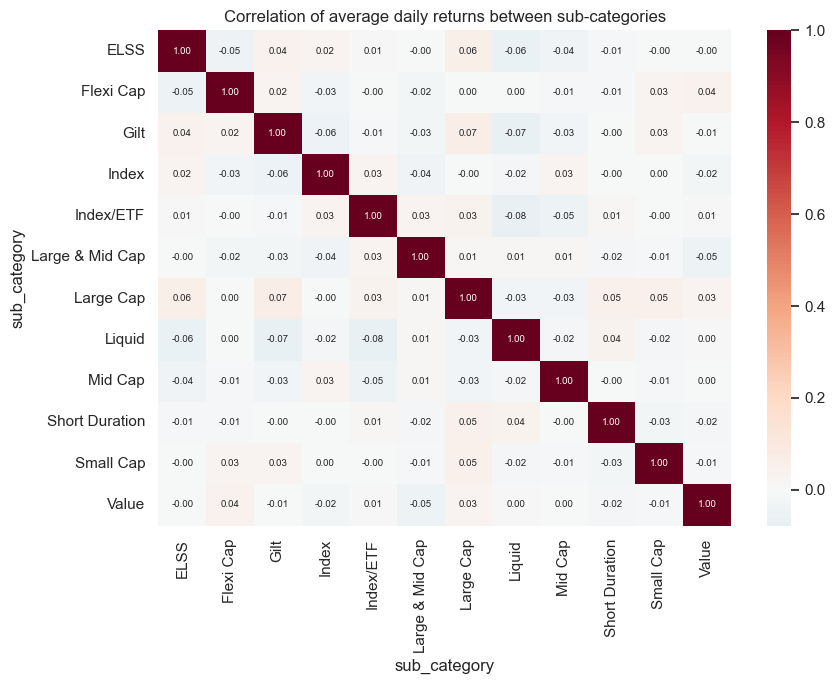

In [12]:
grp = fm.set_index("amfi_code")["sub_category"]
sub_ret = ret.T.groupby(grp).mean().T
plt.figure(figsize=(9, 7))
sns.heatmap(sub_ret.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7})
plt.title("Correlation of average daily returns between sub-categories")
plt.tight_layout(); save_fig("risk_subcategory_correlation"); plt.show()

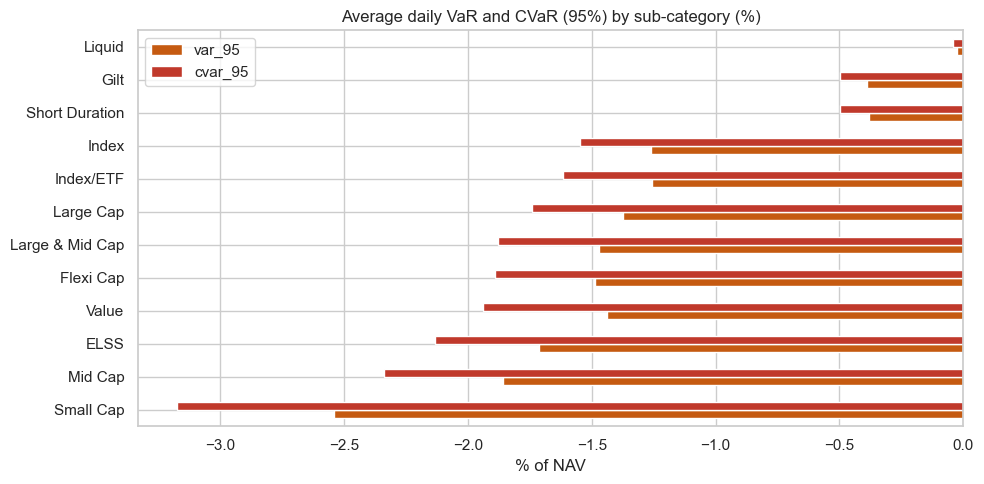

In [13]:
by_sub = risk.groupby("sub_category")[["var_95", "cvar_95"]].mean().mul(100).sort_values("cvar_95")
by_sub.plot.barh(figsize=(10, 5), color=["#C55A11", "#C0392B"])
plt.title("Average daily VaR and CVaR (95%) by sub-category (%)"); plt.xlabel("% of NAV"); plt.ylabel("")
plt.tight_layout(); save_fig("risk_var_cvar"); plt.show()

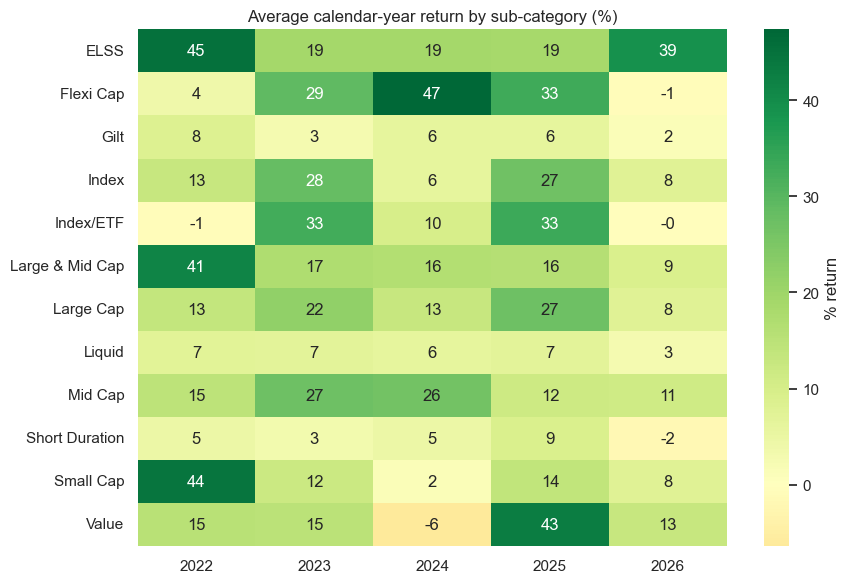

In [14]:
yearly = (1 + ret).groupby(ret.index.year).prod() - 1
yr_sub = yearly.T.groupby(grp).mean().mul(100)
plt.figure(figsize=(9, 6))
sns.heatmap(yr_sub, annot=True, fmt=".0f", cmap="RdYlGn", center=0, cbar_kws={"label": "% return"})
plt.title("Average calendar-year return by sub-category (%)"); plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); save_fig("risk_yearly_returns"); plt.show()

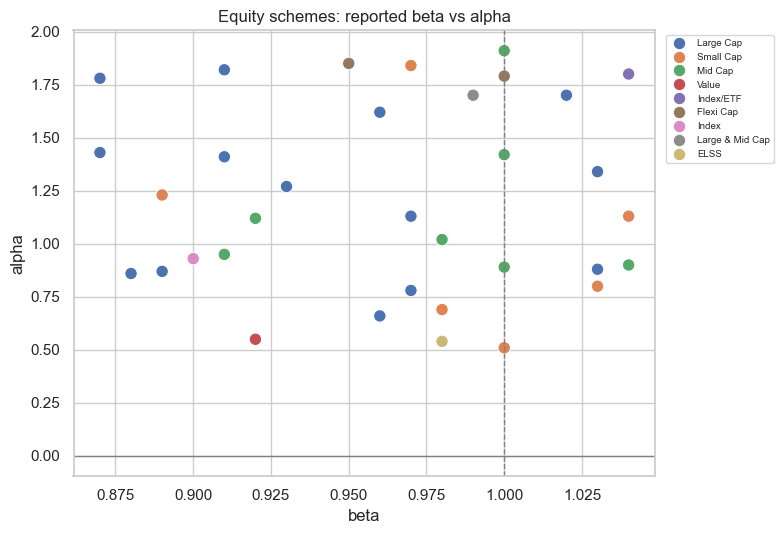

In [15]:
eq = risk[risk["category"] == "Equity"]
# Reported beta/alpha are used for the chart because NAV-derived beta is not meaningful in this dataset (see warning above)
eq_rep = perf[["amfi_code", "beta", "alpha"]].merge(risk[["amfi_code", "category", "sub_category"]], on="amfi_code")
eq_rep = eq_rep[eq_rep["category"] == "Equity"]
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=eq_rep, x="beta", y="alpha", hue="sub_category", s=80)
plt.axhline(0, color="grey", lw=1); plt.axvline(1, color="grey", lw=1, ls="--")
plt.title("Equity schemes: reported beta vs alpha"); plt.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); save_fig("risk_beta_alpha"); plt.show()

In [16]:
worst_days = bm_ret["NIFTY500"].nsmallest(10)
avg_equity = ret[fm.loc[fm["category"] == "Equity", "amfi_code"]].mean(axis=1)
avg_debt = ret[fm.loc[fm["category"] == "Debt", "amfi_code"]].mean(axis=1)
stress = pd.DataFrame({
    "NIFTY500 return %": worst_days * 100,
    "avg equity fund %": avg_equity.reindex(worst_days.index) * 100,
    "avg debt fund %": avg_debt.reindex(worst_days.index) * 100,
})
display(stress.round(2))
print("(If funds do not react on these days, that confirms the weak link between funds and indices noted above.)")
print("On the 10 worst NIFTY500 days, equity funds averaged", f"{stress['avg equity fund %'].mean():.2f}%", "and debt funds", f"{stress['avg debt fund %'].mean():.2f}%")

,NIFTY500 return %,avg equity fund %,avg debt fund %
date,,,
2022-02-21,-2.86,0.02,-0.09
2025-08-15,-2.80,0.54,-0.06
2022-03-22,-2.35,0.04,0.07
2023-03-15,-2.26,-0.06,0.16
2022-11-02,-2.18,-0.03,-0.07
2024-05-09,-2.16,-0.04,-0.01
2023-10-27,-2.15,0.01,-0.01
2022-07-11,-2.14,-0.07,0.11
2022-11-04,-2.09,-0.04,0.11


(If funds do not react on these days, that confirms the weak link between funds and indices noted above.)
On the 10 worst NIFTY500 days, equity funds averaged 0.05% and debt funds 0.02%


In [17]:
out = risk.drop(columns=["bm_index"]).copy()
out.to_csv(PROC / "risk_metrics.csv", index=False)
print("Saved", PROC / "risk_metrics.csv", out.shape)

best = risk.loc[risk["sharpe"].idxmax()]
worst = risk.loc[risk["max_drawdown"].idxmin()]
by_cat = risk.groupby("category")[["cagr", "volatility", "sharpe", "max_drawdown"]].mean()
eq_v, db_v = by_cat.loc["Equity", "volatility"], by_cat.loc["Debt", "volatility"]
findings = [
    f"Best risk-adjusted fund: {best['scheme_name']} (Sharpe {best['sharpe']:.2f}, CAGR {best['cagr']:.1%}).",
    f"Deepest drawdown: {worst['scheme_name']} fell {abs(worst['max_drawdown']):.0%} from its peak.",
    f"Equity funds average {eq_v:.1%} volatility against {db_v:.1%} for debt funds, about {eq_v / db_v:.0f} times as much.",
    f"{int((risk['excess_cagr'] > 0).sum())} of {len(risk)} schemes beat their benchmark on CAGR; the median excess return is {risk['excess_cagr'].median():.1%}.",
    (f"Data check: average fund-vs-benchmark R-squared is only {avg_r2:.2f}, so NAV-derived beta and alpha are not reliable here; use the reported beta/alpha instead."
     if avg_r2 < 0.10 else f"Across equity funds the average beta is {eq['beta'].mean():.2f} and the average annual alpha is {eq['alpha'].mean():.1%}."),
    "Agreement with reported metrics (correlation): " + ", ".join(f"{m} {c:.2f}" for m, c in agree.set_index("metric")["correlation"].items()) + ".",
    f"Historical 95% daily VaR for equity funds averages {risk.loc[risk['category'] == 'Equity', 'var_95'].mean():.2%}: on 1 day in 20 a typical equity fund loses at least that much.",
    f"Risk-free rate assumed: {RF:.1%} (change RF at the top to test sensitivity).",
]
for f in findings:
    print("-", f)

Saved C:\Users\Sakshi Mane\processed\risk_metrics.csv (40, 29)
- Best risk-adjusted fund: Mirae Asset Large Cap Fund - Regular - Growth (Sharpe 1.45, CAGR 31.0%).
- Deepest drawdown: SBI Small Cap Fund - Direct Plan - Growth fell 53% from its peak.
- Equity funds average 17.2% volatility against 2.2% for debt funds, about 8 times as much.
- 23 of 40 schemes beat their benchmark on CAGR; the median excess return is 0.7%.
- Data check: average fund-vs-benchmark R-squared is only 0.00, so NAV-derived beta and alpha are not reliable here; use the reported beta/alpha instead.
- Agreement with reported metrics (correlation): sharpe -0.33, volatility 1.00, max_drawdown 0.32, beta 0.05.
- Historical 95% daily VaR for equity funds averages -1.69%: on 1 day in 20 a typical equity fund loses at least that much.
- Risk-free rate assumed: 6.5% (change RF at the top to test sensitivity).
